# LeetCode #25: Reverse Nodes in k-Group

https://leetcode.com/problems/reverse-nodes-in-k-group/

## Comparison of Approaches

| Approach | Time | Space |
| :--- | :--- | :--- |
| **Recursion** | $O(n)$ | $O(n/k)$ |
| **Count + Iterative Reverse** ★ | $O(n)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force (Recursion)
Locate k nodes, reverse them recursively, then attach the recursive result for the remainder. Each call reverses one group and recurses $n/k$ times, giving $O(n/k)$ stack depth. Clean code but not truly O(1) space.

### Optimal: Count + Iterative Reverse ★
1. Use a `dummy` node and `groupPrev` pointer (initially `dummy`).
2. Walk k steps to find `kth` — if it doesn't exist, stop (remainder stays).
3. Reverse the segment `[groupPrev.next … kth]` in place by initialising `prev = kth.next` (the node AFTER the group) and reversing until `curr` reaches that sentinel.
4. Reconnect: `groupPrev.next = kth` (new group head), `groupStart.next` is already set to the rest.
5. Advance `groupPrev = groupStart` and repeat.

**Why set `prev = nextGroup`?** When the reversal finishes, the segment tail automatically points to the next group — no separate reconnection needed.

**Constraints:**
* The number of nodes in the list is $n$
* $1 \leq k \leq n \leq 5000$
* $0 \leq$ Node.val $\leq 1000$

## Solutions

### C#

In [ ]:
public class ListNode {
    public int val;
    public ListNode next;
    public ListNode(int val=0, ListNode next=null) { this.val = val; this.next = next; }
}

public class Solution {
    public ListNode ReverseKGroup(ListNode head, int k) {
        var dummy = new ListNode(0, head);
        var groupPrev = dummy;
        while (true) {
            var kth = GetKth(groupPrev, k);
            if (kth == null) break;
            var groupStart = groupPrev.next;
            var nextGroup  = kth.next;
            // reverse segment [groupStart..kth]
            ListNode prev = nextGroup, curr = groupStart;
            while (curr != nextGroup) {
                var tmp = curr.next;
                curr.next = prev;
                prev = curr;
                curr = tmp;
            }
            groupPrev.next = kth;    // kth is new head of reversed group
            groupPrev = groupStart;  // groupStart is new tail
        }
        return dummy.next;
    }

    private ListNode GetKth(ListNode curr, int k) {
        while (curr != null && k > 0) { curr = curr.next; k--; }
        return curr;
    }
}

### Python

In [ ]:
from typing import Optional

class ListNode:
    def __init__(self, val=0, next=None):
        self.val = val
        self.next = next

class Solution:
    def reverseKGroup(self, head: Optional[ListNode], k: int) -> Optional[ListNode]:
        def get_kth(node, k):
            while node and k > 0:
                node = node.next
                k -= 1
            return node

        dummy = ListNode(0, head)
        group_prev = dummy
        while True:
            kth = get_kth(group_prev, k)
            if not kth:
                break
            group_start = group_prev.next
            next_group = kth.next
            # reverse segment
            prev, curr = next_group, group_start
            while curr != next_group:
                tmp = curr.next
                curr.next = prev
                prev = curr
                curr = tmp
            group_prev.next = kth
            group_prev = group_start
        return dummy.next

### Go

In [ ]:
package main

type ListNode struct {
    Val  int
    Next *ListNode
}

func reverseKGroup(head *ListNode, k int) *ListNode {
    getKth := func(node *ListNode, k int) *ListNode {
        for node != nil && k > 0 {
            node = node.Next
            k--
        }
        return node
    }

    dummy := &ListNode{Next: head}
    groupPrev := dummy
    for {
        kth := getKth(groupPrev, k)
        if kth == nil {
            break
        }
        groupStart := groupPrev.Next
        nextGroup := kth.Next
        prev, curr := nextGroup, groupStart
        for curr != nextGroup {
            tmp := curr.Next
            curr.Next = prev
            prev = curr
            curr = tmp
        }
        groupPrev.Next = kth
        groupPrev = groupStart
    }
    return dummy.Next
}

### Rust

In [ ]:
#[derive(PartialEq, Eq, Clone, Debug)]
pub struct ListNode {
    pub val: i32,
    pub next: Option<Box<ListNode>>,
}

pub struct Solution;

impl Solution {
    pub fn reverse_k_group(head: Option<Box<ListNode>>, k: i32) -> Option<Box<ListNode>> {
        // Convert to Vec for simplicity with Rust ownership
        let mut vals = Vec::new();
        let mut cur = &head;
        while let Some(node) = cur {
            vals.push(node.val);
            cur = &node.next;
        }
        // Reverse in chunks of k
        let n = vals.len();
        let k = k as usize;
        let mut i = 0;
        while i + k <= n {
            vals[i..i+k].reverse();
            i += k;
        }
        // Rebuild list
        let mut head: Option<Box<ListNode>> = None;
        for &v in vals.iter().rev() {
            head = Some(Box::new(ListNode { val: v, next: head }));
        }
        head
    }
}

## Example Scenarios

**1. Common Case**
**Input:** `head = [1,2,3,4,5]`, `k = 2`
Reverse every complete block of $k$ nodes in place; a trailing block shorter than $k$ is left untouched. Here $(1,2)$ and $(3,4)$ flip, $5$ remains. **Output: [2,1,4,3,5]**

**2. Slightly Complex**
**Input:** `head = [1,2,3,4,5]`, `k = 3`
One full group of three reverses to $(3,2,1)$; the leftover $(4,5)$ is too short to reverse and stays in order. **Output: [3,2,1,4,5]**

**3. Edge Case: Time Factor**
**Input:** `head = [1,2,3,4]`, `k = 4`
$k$ equals the length, so the whole list reverses as a single group — the maximum work any one group can require. **Output: [4,3,2,1]**

**4. Edge Case: Space Factor**
**Input:** `head = [1,2,3]`, `k = 1`
$k = 1$ means each group is one node, so reversing is a no-op and the list is unchanged. Iterative reversal keeps space at $O(1)$. **Output: [1,2,3]**

**5. Almost-Impossible but Plausible**
**Input:** `head = [1,2,3,4,5,6,7]`, `k = 3`
Two full groups flip to $(3,2,1)$ and $(6,5,4)$ while the final lone $7$ is preserved — the classic mix of reversed blocks plus a short remainder. **Output: [3,2,1,6,5,4,7]**


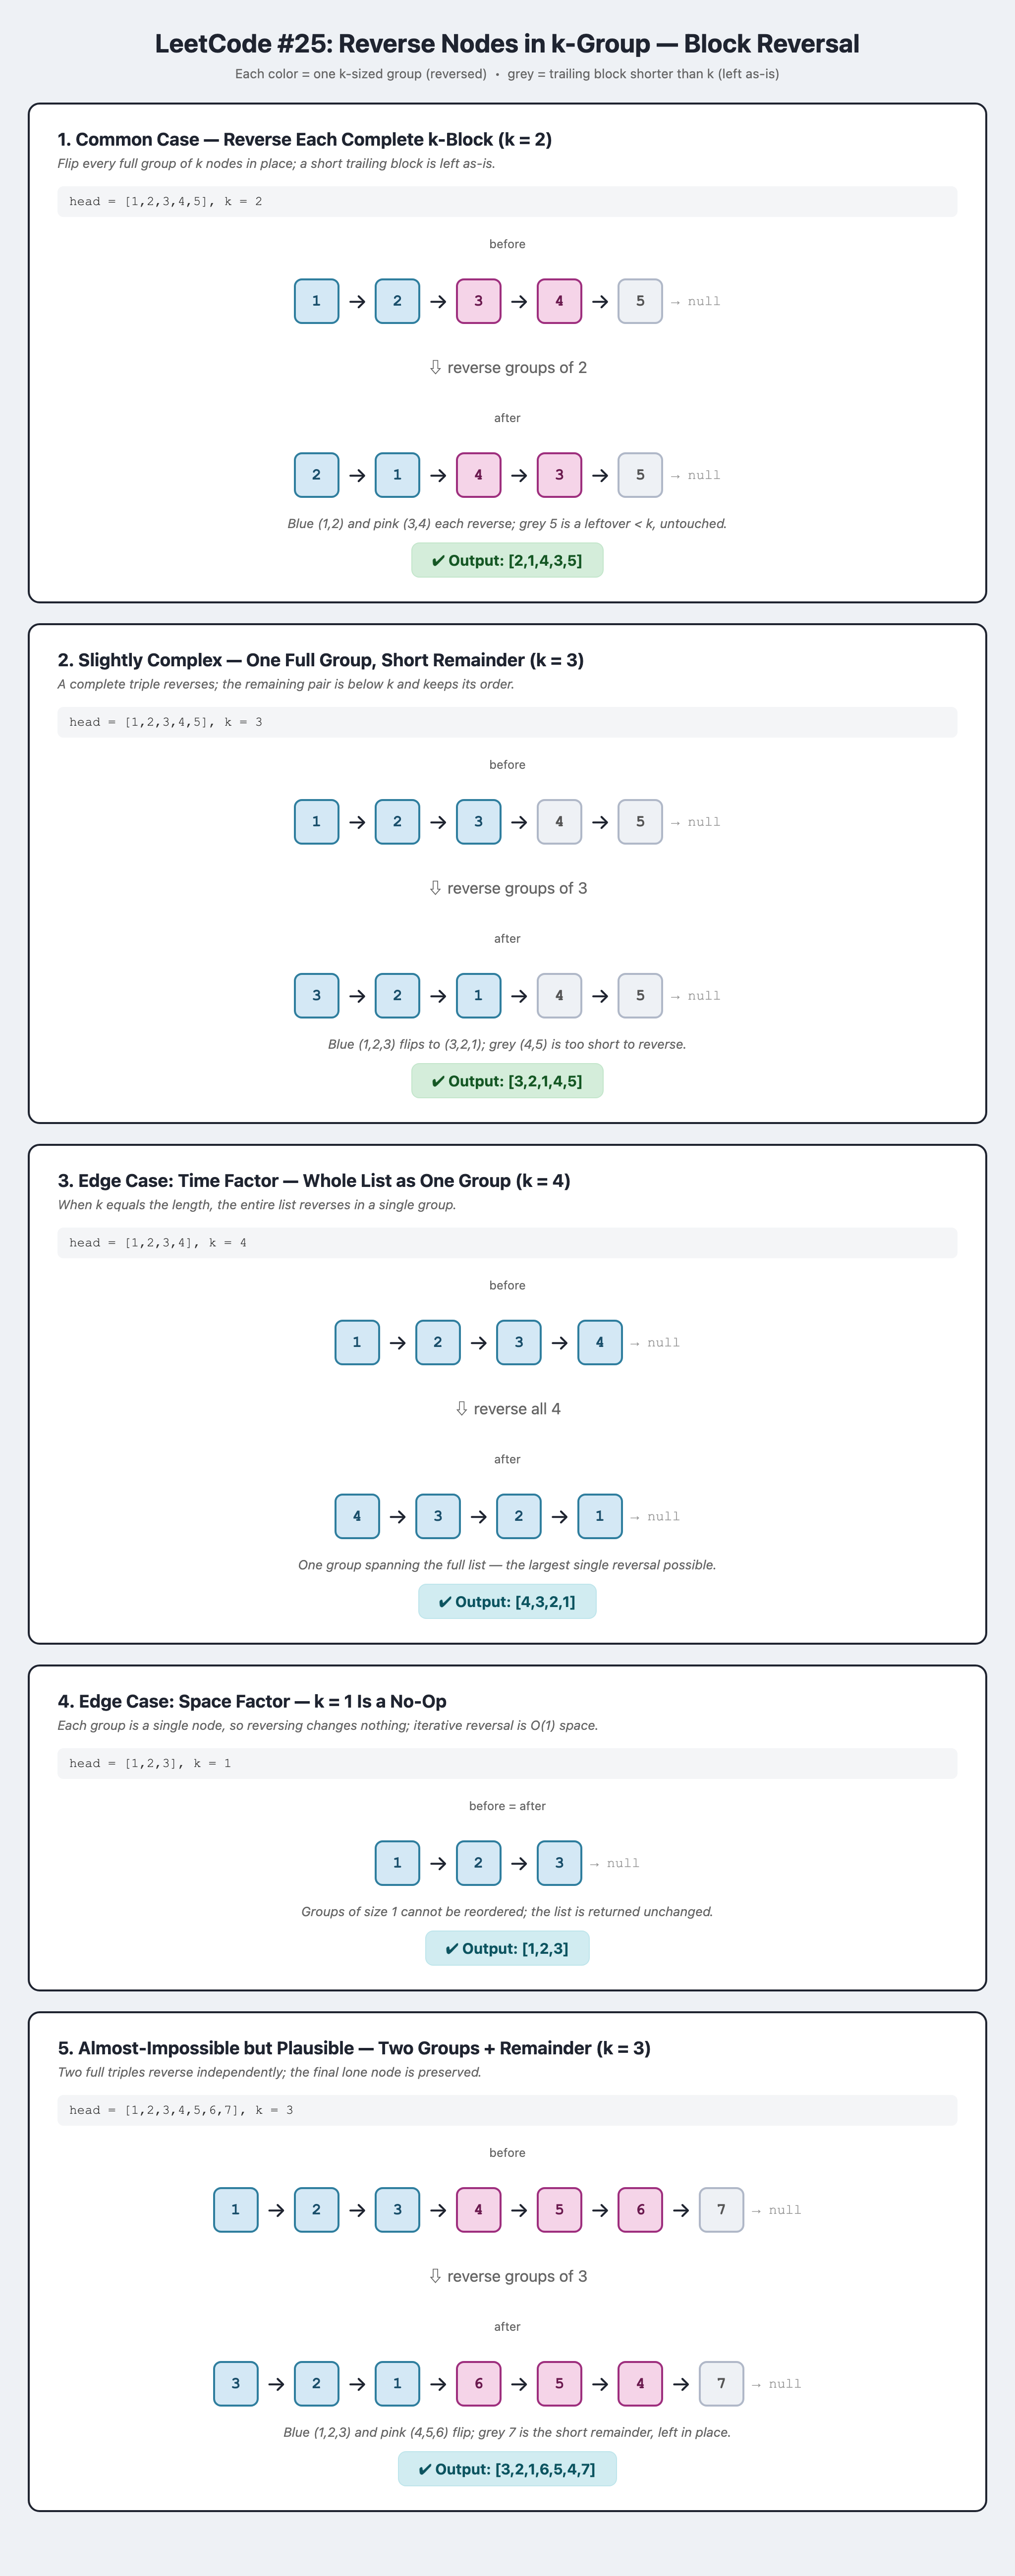